Цель - построить классификационную модель, которая определяет наличие депрессии у студента

Задачи:
1. Провести EDA
2. Выбрать подходящие модели
3. Подготовить данные для ML
4. Обучить модели
5. Оценить их точность, выбрать наиболее качественную

# 1. EDA


In [5]:
import pandas as pd

df = pd.read_excel('Student_Depression_Dataset.xlsx')

In [6]:
df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [7]:
df.tail()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
4459,Female,26,Middle class,In a Relationship,Separated,Family,11,2.97,No,Critical,12619,Khulna,Yes
4460,Male,28,Lower Middle class,Single,Unmarried,Family,8,2.60,No,Normal,2806,Rajshahi,Yes
4461,Female,23,Middle class,In a Relationship,Married,Bachelor,10,2.80,No,Good,14066,Rajshahi,No
4462,Female,23,Middle class,Complicated,Married,Family,5,3.00,Yes,Normal,14338,Barisal,No
4463,Female,21,Lower Middle class,Single,Unmarried,Family,5,2.56,Yes,Abnormal,4000,Barisal,Yes


In [8]:
df.sample(5)

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
3212,Male,25,Middle class,Single,Unmarried,Bachelor,8,3.73,No,Normal,6400,Barisal,No
2407,Female,23,Rich class,In a Relationship,Unmarried,Family,7,2.73,Yes,Normal,7100,Rangpur,No
1366,Female,21,Middle class,In a Relationship,Unmarried,Bachelor,5,3.39,No,Critical,15623,Mymensingh,Yes
358,Male,23,Middle class,In a Relationship,Unmarried,Family,6,3.55,Yes,Normal,11080,Barisal,No
1159,Female,24,Middle class,In a Relationship,Unmarried,Bachelor,7,3.89,Yes,Abnormal,10025,Chittagong,No


In [9]:
df.shape

(4464, 13)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   object 
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 453.5+ KB


Пропусков в данных нет, данные типизированы правильно

In [11]:
df.describe()

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


In [12]:
#Аномалий в возрасте нет. максимальное количество семестров - 13, минимальный - 0. Погуглил, нулевой семестр - это подготовительный курс.
# CGPA соответствует реальности (минимум 2.25, максимум 4)

### Анализ категориальных данных

In [13]:
cat_columns = ['Depression', 'Family_background', 'Relationship_status', 'Marital_status', 'Living_style', 'Health_condition', 'Home_division']

for i in cat_columns:
    print(f'Значения в колонке {i:<19} : {df[i].unique()} ')

Значения в колонке Depression          : ['Yes' 'No'] 
Значения в колонке Family_background   : ['Middle class' 'Lower Middle class' 'Rich class'] 
Значения в колонке Relationship_status : ['Single' 'Complicated' 'In a Relationship'] 
Значения в колонке Marital_status      : ['Unmarried' 'Married' 'Separated'] 
Значения в колонке Living_style        : ['Bachelor' 'Family'] 
Значения в колонке Health_condition    : ['Critical' 'Abnormal' 'Good' 'Normal'] 
Значения в колонке Home_division       : ['Chittagong' 'Dhaka' 'Rajshahi' 'Mymensingh' 'Barisal' 'Rangpur' 'Khulna'
 'Sylhet'] 


преобразуем целевую переменную в булевый тип.

In [14]:
df.Depression = df.Depression == 'Yes'
df.Depression.head()

0     True
1     True
2     True
3    False
4     True
Name: Depression, dtype: bool

Проверим, что в каждой подгруппе достаточно данных, чтобы наша модель не переобучилась на шуме из-за редких категорий

In [15]:
for i in cat_columns:
    print(df.groupby([i]).size(), '\n')

Depression
False    3263
True     1201
dtype: int64 

Family_background
Lower Middle class    1151
Middle class          2642
Rich class             671
dtype: int64 

Relationship_status
Complicated           204
In a Relationship    1457
Single               2803
dtype: int64 

Marital_status
Married       725
Separated     120
Unmarried    3619
dtype: int64 

Living_style
Bachelor    2449
Family      2015
dtype: int64 

Health_condition
Abnormal     881
Critical     634
Good        1162
Normal      1787
dtype: int64 

Home_division
Barisal        355
Chittagong     400
Dhaka         1527
Khulna         548
Mymensingh     338
Rajshahi       488
Rangpur        363
Sylhet         445
dtype: int64 



Редкие категории (n < 50) в датасете отсутствуют

### Анализ числовых данных
Перейдем к числовым данным.

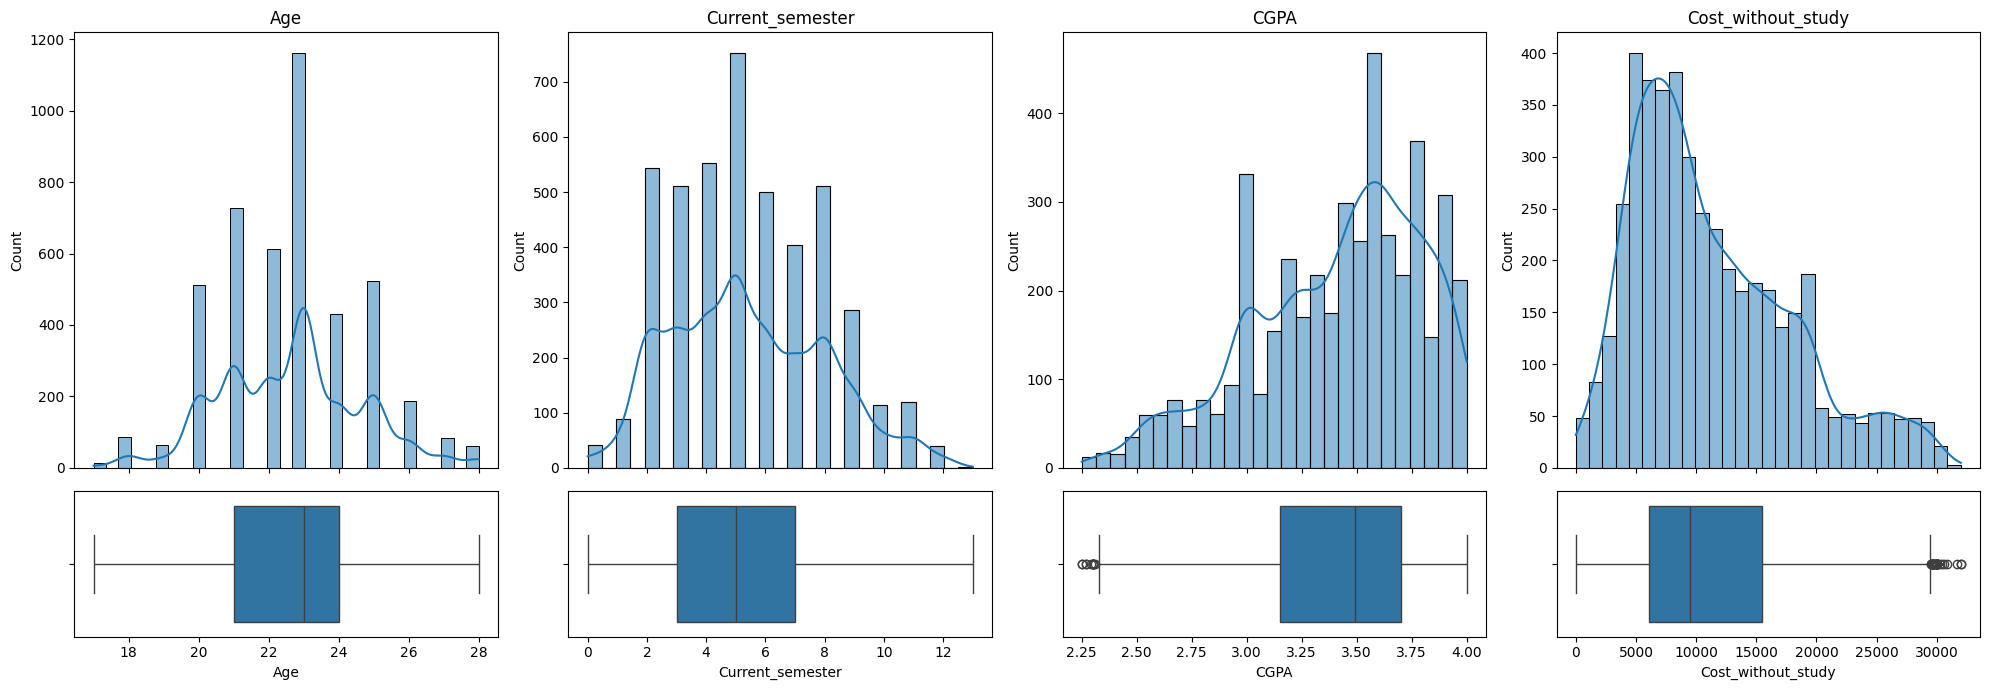

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

num_columns = ['Age', 'Current_semester', 'CGPA', 'Cost_without_study']

fig, axes = plt.subplots(
    2, len(num_columns),
    figsize=(5 * len(num_columns), 7),
    gridspec_kw={'height_ratios': [3, 1]},   # гистограмма выше боксплота
    sharex='col',                            # общая ось X по колонкам
)

for i, col in enumerate(num_columns):
    ax_hist = axes[0, i]
    ax_box  = axes[1, i]

    # Гистограмма
    sns.histplot(data=df, x=col, kde=True, ax=ax_hist)
    ax_hist.set_title(col)
    ax_hist.set_xlabel('')                   # убираем дублирующую подпись

    # Боксплот — горизонтальный, чтобы ось X совпадала с гистограммой
    sns.boxplot(data=df, x=col, ax=ax_box)
    ax_box.set_xlabel(col)

plt.tight_layout()
plt.show()

Присутствуют единичные выбросы в CGPA и Cost_without_study. средний балл 2.25 - 2.4 возможен, поэтому не удаляем эти данные. Цена за обучение так же может быть больше 30 000.

In [17]:
df.duplicated().sum()

np.int64(0)

Дубликаты отсутствуют

Построим матрицу корелляций, чтобы исключить мультиколлинеарность

In [19]:
numeric_df = df[['Depression', 'Age', 'Current_semester', 'CGPA', 'Cost_without_study']] 
corr_matrix = numeric_df.corr()
corr_matrix

,Depression,Age,Current_semester,CGPA,Cost_without_study
Depression,1.000000,-0.033871,-0.017801,-0.096266,0.018222
Age,-0.033871,1.000000,0.325304,-0.065085,-0.062625
Current_semester,-0.017801,0.325304,1.000000,-0.007946,0.013762
CGPA,-0.096266,-0.065085,-0.007946,1.000000,0.081900
Cost_without_study,0.018222,-0.062625,0.013762,0.081900,1.000000


<Axes: >

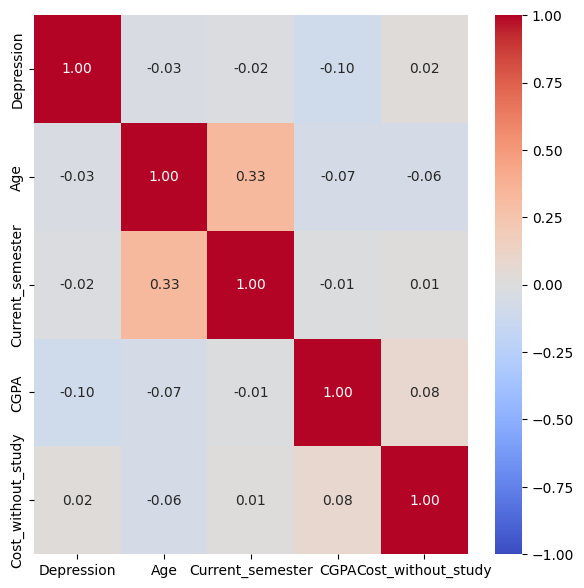

In [20]:
plt.figure(figsize=(7, 7))
sns.heatmap(
    corr_matrix, 
    annot=True,        # Показывать числа внутри ячеек
    fmt=".2f",         # Округление до 2 знаков после запятой
    cmap='coolwarm',   # Цветовая схема (синий - минус, красный - плюс)
    vmin=-1, vmax=1    # Границы шкалы от -1 до 1
)

In [ ]:
Мультиколлинеарность у признаков отсутствует

### Вывод: 
- в датасете 4463 строки, 13 признаков
- пропуски и дубликаты отсутствуют
- колонки CGPA и Cost_without_study скошены, в зависимости от модели будет необходимо их выровнять
- Мультиколлинеарность между данными отсутствует

# 2 Выбор моделей машинного обучения


# Подготовка данных (preproccesing)

Сделаем разделение данных

In [24]:
from sklearn.model_selection import train_test_split

# Отделим признаки от целевой переменной
X = df.drop(columns='Depression')
y = df['Depression']

# Разделим данные
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [26]:
#Создадим списки с названиями категориальных и числовых колонок
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cat_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

num_features = X.select_dtypes(
    include=['number']
).columns.tolist()

In [29]:
#Преобразуем данные для логистической регрессии
preprocessor_lr = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
])

In [28]:
#для Decision Tree и Random Forest
preprocessor_tree = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
])


# Обучение моделей

In [30]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    'Logistic Regression': Pipeline([
        ('preprocessor', preprocessor_lr),
        ('model', LogisticRegression(max_iter=1000))
    ]),

    'Decision Tree': Pipeline([
        ('preprocessor', preprocessor_tree),
        ('model', DecisionTreeClassifier(
            max_depth=5,
            random_state=42
        ))
    ]),

    'Random Forest': Pipeline([
        ('preprocessor', preprocessor_tree),
        ('model', RandomForestClassifier(
            n_estimators=300,
            max_depth=10,
            random_state=42
        ))
    ])
}

In [31]:
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    print(f'{name} обучена')

Logistic Regression обучена
Decision Tree обучена
Random Forest обучена


# Оценка моделей

In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

results = []

for name, pipeline in models.items():

    #Получаем предсказания классов
    y_pred = pipeline.predict(X_test)

    #Получаем вероятности положительного класса (True)
    positive_class_index = list(pipeline.classes_).index(True)
    y_proba = pipeline.predict_proba(X_test)[:, positive_class_index]

    #Считаем метрики
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, pos_label=True),
        'Recall': recall_score(y_test, y_pred, pos_label=True),
        'F1': f1_score(y_test, y_pred, pos_label=True),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })

results_df = pd.DataFrame(results).set_index('Model')

results_df.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.971,0.961,0.929,0.945,0.993
Decision Tree,0.980,1.000,0.925,0.961,0.993
Random Forest,0.989,0.996,0.962,0.979,0.999


In [ ]:
# Вывод
Random Forest наиболее точно предсказывает наличие депрессиии у студентов

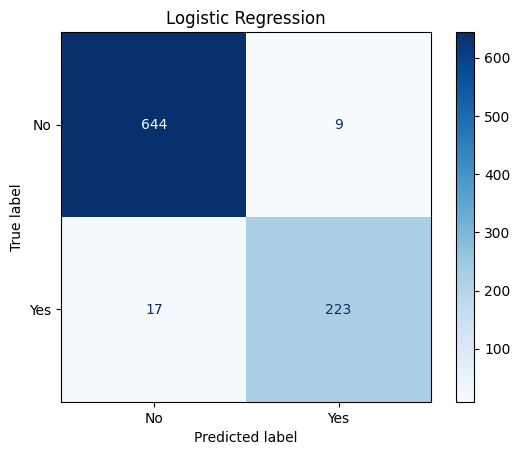

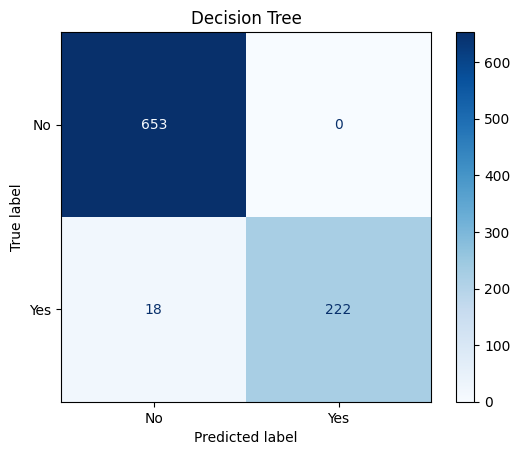

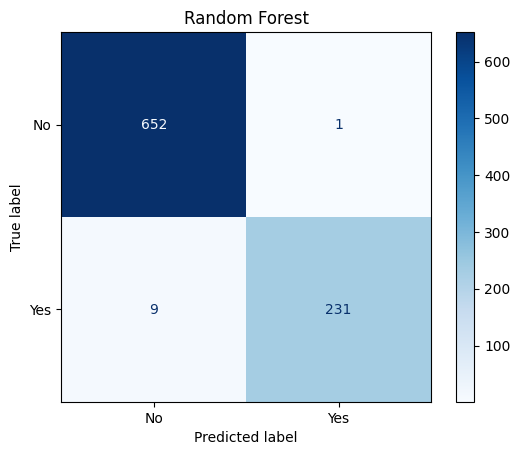

In [39]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, pipeline in models.items():

    y_pred = pipeline.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[False, True],
        display_labels=['No', 'Yes'],
        cmap='Blues'
    )

    plt.title(name)
    plt.show()